# P5 – Hit Predictor

## What this part does

This notebook answers the most interesting question in the project: **can we tell from sound alone whether a song will be a hit, and what makes a hit?** A song counts as a **hit if its Spotify popularity is 70 or more** (about 9% of our songs).

We train three tree-based models: a single **decision tree**, a **Random Forest** (bagging) and **AdaBoost** (boosting). Because hits are rare we handle **class imbalance** and judge the models with F1 and ROC-AUC instead of plain accuracy. In the app, the **Hit Predictor** shows a hit chance for any song (from the best model, with calibrated probabilities) plus the reasons behind it (e.g. "high danceability, low acousticness").

## Concepts in plain English

**Decision tree.** A tree asks a series of yes/no questions ("danceability > 0.7?", "acousticness < 0.2?") until it reaches a leaf that says *hit* or *not hit*. At each step it picks the question that makes the two resulting groups as **pure** as possible (each group mostly hits or mostly non-hits).
- **Gini impurity** = the chance that two songs picked at random from a group have different labels: 0 for a pure group, highest for a 50/50 mix.
- **Entropy** = how "surprising" the labels in a group are, −Σ p·log₂p; also 0 for a pure group. **Information gain** = how much a split lowers the entropy.
- **Depth and overfitting:** a very deep tree can keep asking questions until every training song is in its own pure leaf. It memorises the training data and fails on new songs. Limiting the depth (choosing it by cross-validation) is a form of **pruning**.

**Ensembles.**
- **Random Forest (bagging):** train many trees, each on a random **bootstrap sample** of the songs (drawn with replacement) and considering a random subset of features at each split, then let them **vote** (average their probabilities). Individual trees are noisy, but their errors partly cancel out, so averaging **reduces variance**: a forest is much more stable than one tree.
- **AdaBoost (boosting):** train very small trees (**stumps**, a single question each) **one after another**. After each stump, the songs it got wrong get **more weight**, so the next stump focuses on them. The final prediction is a weighted vote of all stumps (better stumps get bigger votes). Boosting mainly **reduces bias**: many weak learners add up to a strong one.

**Class imbalance.** Only ~9% of songs are hits. A "model" that always says *not hit* is 91% accurate and completely useless. So:
- **class weights** make a missed hit cost more during training (here about 10× more than a missed non-hit, `class_weight="balanced"`);
- we judge models by **precision** (of the songs we call hits, how many really are?), **recall** (of the real hits, how many do we catch?), **F1** (their balance) and **ROC-AUC**.

**ROC-AUC.** A model gives each song a hit score. The **ROC curve** plots, for every possible threshold, the share of real hits caught (true-positive rate) against the share of non-hits wrongly flagged (false-positive rate). **AUC** (area under the curve) = the probability that a randomly chosen hit gets a higher score than a randomly chosen non-hit. **0.5 = random guessing, 1.0 = perfect ranking.**

**Feature importance.** How much each feature reduces impurity across all the splits in the forest, averaged over trees. It shows which features the model *relies on*, which is not necessarily what *causes* a hit.

**Calibration.** When a model says "30% hit chance", do about 30% of such songs turn out to be hits? Class weights distort probabilities (they inflate hit chances on purpose), so we **calibrate**: learn a mapping from raw scores to honest probabilities with cross-validation (`CalibratedClassifierCV`). A **reliability plot** compares predicted and observed hit rates.

## Setup

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_curve, brier_score_loss
from sklearn.utils.class_weight import compute_sample_weight

from src import data, evaluate
from src.style import setup_notebook_style

np.random.seed(42)
setup_notebook_style()
pd.set_option("display.width", 160, "display.precision", 3)
FIG = data.ROOT / "results" / "figures" / "p5_hit"
MODELS = data.ROOT / "models" / "p5_hit"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test, feature_names = data.load_splits()
ytr, yte = y_train["hit"], y_test["hit"]
print(f"Hit threshold: popularity >= {data.HIT_THRESHOLD}")
print(f"Train: {len(ytr)} songs, {ytr.sum()} hits ({ytr.mean():.1%})   Test: {len(yte)} songs, {yte.sum()} hits ({yte.mean():.1%})")
print("Popularity is NOT an input:", "popularity" not in feature_names)

Hit threshold: popularity >= 70
Train: 3413 songs, 314 hits (9.2%)   Test: 854 songs, 65 hits (7.6%)
Popularity is NOT an input: True


## 1. The imbalance problem in numbers
What would "always predict not-hit" score?

In [2]:
always_no = np.zeros(len(yte), dtype=int)
m0 = evaluate.classification_metrics(yte, always_no)
songs, _ = data.load_all_songs()
print(f"'Always not-hit' on the test set: accuracy {m0['accuracy']:.1%}, recall {m0['recall']:.0%}, F1 {m0['f1']:.2f}")
print("\nHit rate by genre (all songs):")
print(songs.groupby("track_genre").hit.mean().sort_values(ascending=False).map("{:.1%}".format).to_string())

'Always not-hit' on the test set: accuracy 92.4%, recall 0%, F1 0.00

Hit rate by genre (all songs):
track_genre
edm            23.7%
hip-hop        17.7%
country        10.9%
jazz            4.0%
classical       0.9%
heavy-metal     0.0%


This shows the **accuracy paradox**: always saying "not a hit" scores **92.4% accuracy** on the test set while catching **0%** of hits (F1 = 0). So accuracy is useless here. It also shows hits are very unevenly spread: edm (23.7%) and hip-hop (17.7%) have many hits, while **heavy-metal has none at all** (its most popular song has popularity 62). Our models will partly learn "sounds like edm/hip-hop" as a sign of a hit.

## 2. Decision tree: tune depth and criterion with cross-validation
5-fold stratified CV on the training set, scored by ROC-AUC (it does not depend on a threshold, so it is stable with few hits). `class_weight="balanced"` handles the imbalance.

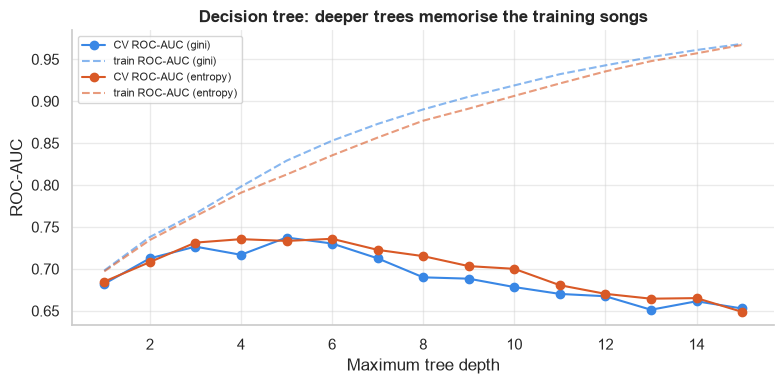

Best: {'criterion': 'gini', 'max_depth': 5} CV ROC-AUC 0.737


In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
tree_grid = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=42),
                         {"max_depth": list(range(1, 16)), "criterion": ["gini", "entropy"]},
                         cv=cv, scoring="roc_auc", return_train_score=True, n_jobs=-1).fit(X_train, ytr)
tree = tree_grid.best_estimator_
res = pd.DataFrame(tree_grid.cv_results_)
fig, ax = plt.subplots(figsize=(8, 4))
for crit, color in [("gini", "#3987e5"), ("entropy", "#d95926")]:
    d = res[res.param_criterion == crit]
    ax.plot(d.param_max_depth, d.mean_test_score, marker="o", color=color, label=f"CV ROC-AUC ({crit})")
    ax.plot(d.param_max_depth, d.mean_train_score, ls="--", color=color, alpha=.6, label=f"train ROC-AUC ({crit})")
ax.set_xlabel("Maximum tree depth"); ax.set_ylabel("ROC-AUC"); ax.legend(fontsize=8)
ax.set_title("Decision tree: deeper trees memorise the training songs")
plt.tight_layout(); plt.savefig(FIG / "tree_depth.png", dpi=120); plt.show()
print("Best:", tree_grid.best_params_, "CV ROC-AUC %.3f" % tree_grid.best_score_)

This shows overfitting in action: **training ROC-AUC keeps rising towards 1.0 as the tree gets deeper** (it memorises the training songs), while **CV ROC-AUC peaks at depth 5 (0.737)** and then falls. Gini and entropy give almost the same curves. CV picked **Gini with max_depth = 5**: deep enough to find patterns, shallow enough to generalise.

## 3. Random Forest (bagging)
300 trees, each on a bootstrap sample with random feature subsets. We tune tree depth and minimum leaf size by CV.

In [4]:
rf_grid = GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1),
                       {"max_depth": [4, 6, 8, 12, None], "min_samples_leaf": [1, 5, 10]},
                       cv=cv, scoring="roc_auc").fit(X_train, ytr)
rf = rf_grid.best_estimator_
print("Best:", rf_grid.best_params_, "CV ROC-AUC %.3f" % rf_grid.best_score_)

Best: {'max_depth': None, 'min_samples_leaf': 10} CV ROC-AUC 0.790


## 4. AdaBoost with decision stumps (boosting)
Each weak learner is a stump (`max_depth=1`). Imbalance is handled by giving hit songs a larger starting weight (balanced sample weights). We tune the number of stumps and the learning rate (how much each stump's vote counts).

In [5]:
sw = compute_sample_weight("balanced", ytr)
ada_grid = GridSearchCV(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=42),
                        {"n_estimators": [50, 100, 200, 400], "learning_rate": [0.05, 0.1, 0.5, 1.0]},
                        cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, ytr, sample_weight=sw)
ada = ada_grid.best_estimator_
print("Best:", ada_grid.best_params_, "CV ROC-AUC %.3f" % ada_grid.best_score_)

Best: {'learning_rate': 0.5, 'n_estimators': 200} CV ROC-AUC 0.782


## 5. Test-set results: F1, precision, recall, ROC-AUC

In [6]:
models = {"Decision tree": tree, "Random Forest": rf, "AdaBoost (stumps)": ada}
rows = {}
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    met = evaluate.classification_metrics(yte, m.predict(X_test), proba)
    evaluate.log_score("P5 Hit Predictor", name, "hit", met)
    evaluate.save_predictions("hit", name, X_test.index, m.predict(X_test), proba, y_true=yte)
    rows[name] = met
cv_auc = {"Decision tree": tree_grid.best_score_, "Random Forest": rf_grid.best_score_, "AdaBoost (stumps)": ada_grid.best_score_}
tab = pd.DataFrame(rows).T[["f1", "precision", "recall", "roc_auc", "accuracy"]]
tab.insert(0, "CV ROC-AUC (train)", pd.Series(cv_auc))
tab.round(3)

,CV ROC-AUC (train),f1,precision,recall,roc_auc,accuracy
Decision tree,0.737,0.256,0.153,0.769,0.729,0.659
Random Forest,0.790,0.262,0.203,0.369,0.784,0.842
AdaBoost (stumps),0.782,0.241,0.141,0.846,0.757,0.595


This shows that the **ensembles rank songs better than one tree**: Random Forest has the best ROC-AUC (CV 0.790, test **0.784**), AdaBoost is close (0.782 / 0.757) and the single tree is lowest (0.737 / 0.729). F1 is modest for all (about 0.25) because hits are rare and hard to spot from sound. The models make different trade-offs at the default threshold: the tree and AdaBoost catch most hits (recall 0.77–0.85) but raise many false alarms (precision ~0.15); the forest is more cautious (recall 0.37, precision 0.20). Every model is far better than the random baseline (F1 0.03, ROC-AUC 0.46).

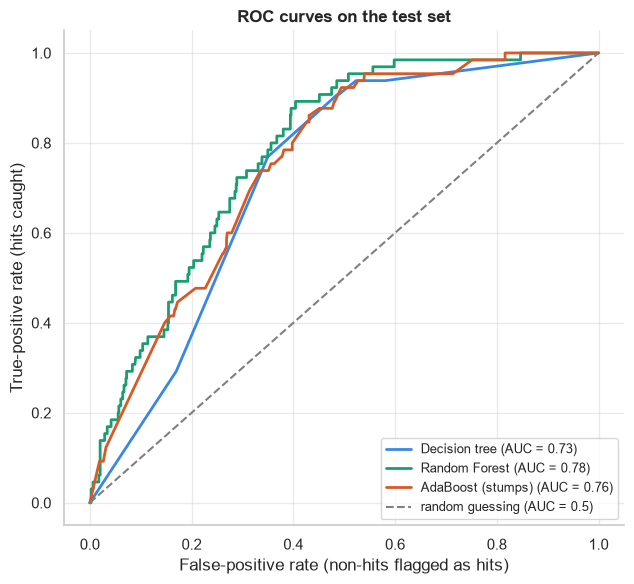

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, m), color in zip(models.items(), ["#3987e5", "#199e70", "#d95926"]):
    fpr, tpr, _ = roc_curve(yte, m.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {rows[name]['roc_auc']:.2f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="random guessing (AUC = 0.5)")
ax.set_xlabel("False-positive rate (non-hits flagged as hits)"); ax.set_ylabel("True-positive rate (hits caught)")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "roc_curves.png", dpi=120); plt.show()

This shows all three curves well above the diagonal (random guessing). The **Random Forest curve (AUC 0.78) lies on top for most thresholds**: for any accepted false-alarm rate it catches at least as many hits as the others. E.g. it catches roughly 70% of hits while flagging about 25% of non-hits.

## 6. Rules for a hit: the top 3 levels of a decision tree
For readability we draw a depth-3 tree (trained the same way). Each box shows the question, the impurity, the number of songs and the (class-weighted) share of non-hits vs hits; orange-ish boxes lean "not hit", blue-ish boxes lean "hit". Feature values are in **scaled units** (0 = average song; we translate the thresholds below).

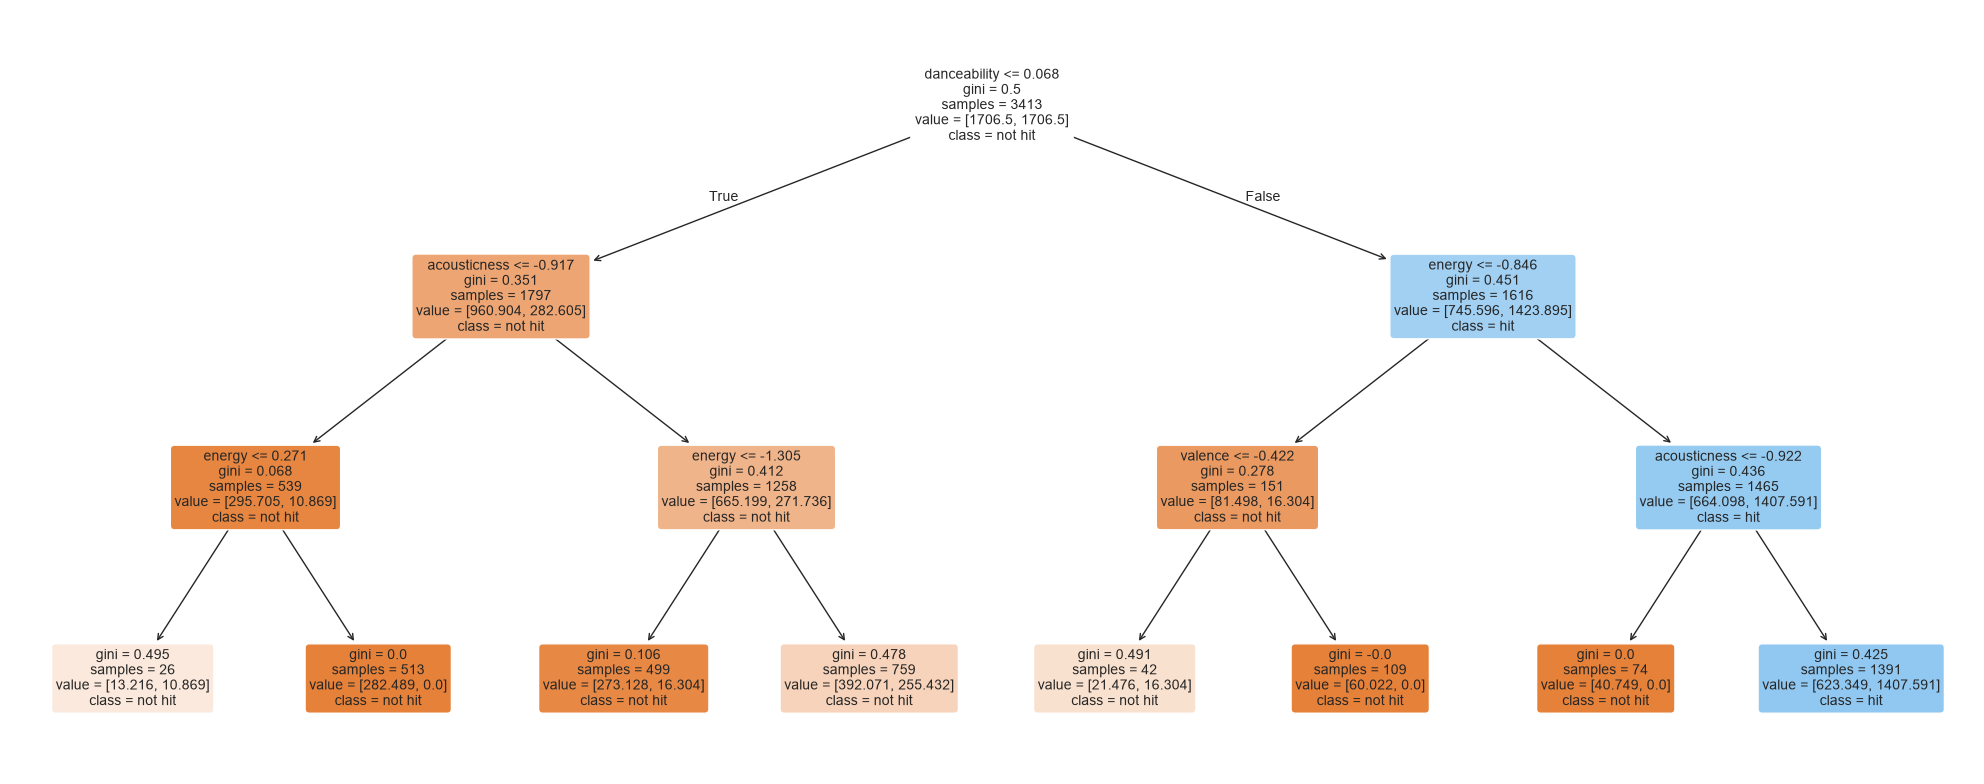

Split thresholds translated back to real units:
  node 0: danceability <= 0.545  (scaled 0.07)
  node 1: acousticness <= 0.003  (scaled -0.92)
  node 2: energy <= 0.682  (scaled 0.27)
  node 5: energy <= 0.219  (scaled -1.30)
  node 8: energy <= 0.354  (scaled -0.85)
  node 9: valence <= 0.351  (scaled -0.42)
  node 12: acousticness <= 0.001  (scaled -0.92)


In [8]:
small_tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", criterion=tree_grid.best_params_["criterion"],
                                    random_state=42).fit(X_train, ytr)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(small_tree, feature_names=feature_names, class_names=["not hit", "hit"], filled=True, rounded=True,
          fontsize=10, impurity=True, proportion=False, ax=ax)
plt.tight_layout(); plt.savefig(FIG / "tree_top3.png", dpi=110); plt.show()

scaler = data.load_scaler()
def unscale(feat, z):
    i = feature_names.index(feat)
    return z * scaler.scale_[i] + scaler.mean_[i]
t = small_tree.tree_
print("Split thresholds translated back to real units:")
for node in range(t.node_count):
    if t.children_left[node] != -1:
        f = feature_names[t.feature[node]]
        print(f"  node {node}: {f} <= {unscale(f, t.threshold[node]):.3f}  (scaled {t.threshold[node]:.2f})")

This shows the "rules for a hit" in plain words:
1. **Is the song danceable (danceability > 0.545)?** This is the first and most important question. Not danceable → mostly not a hit.
2. Among **non-danceable** songs, ones with almost **zero acousticness (≤ 0.003: typical of heavy-metal's distorted guitars)** are pure non-hits (513 songs, 0 hits); very quiet, low-energy pieces (classical) are also non-hits.
3. Among **danceable** songs, those with **reasonable energy (> 0.354)** and **some acoustic element (acousticness > 0.001)** form the big "hit-leaning" leaf (1,391 songs, about 69% hits after class weighting). In short: *danceable, energetic, not purely acoustic and not metal-style distorted*.

## 7. What makes a hit? Feature importance from the forest

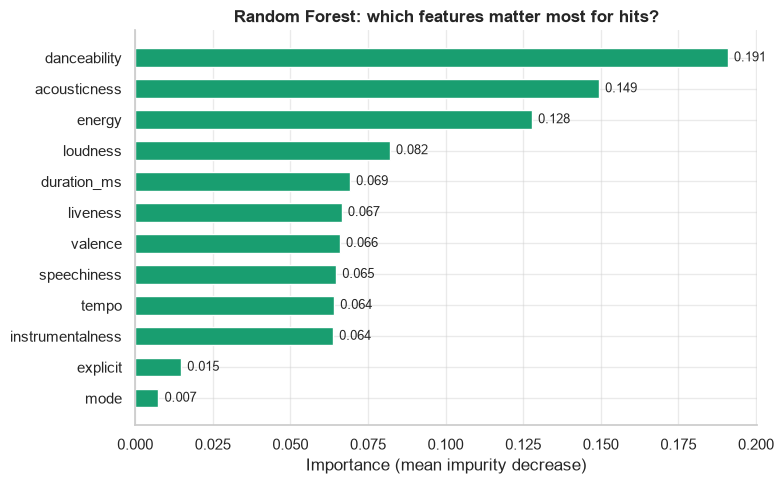

,non-hits (avg),hits (avg)
danceability,0.519,0.661
acousticness,0.364,0.222
energy,0.596,0.669
loudness,-9.582,-6.579
duration_ms,224589.747,206703.525
liveness,0.207,0.167
valence,0.444,0.491
speechiness,0.073,0.089


In [9]:
imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color="#199e70", height=0.6)
for i, v in enumerate(top.values):
    ax.text(v + .002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Importance (mean impurity decrease)"); ax.set_title("Random Forest: which features matter most for hits?")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=120); plt.show()

train_songs = songs[songs.split == "train"]          # training songs only: no test labels used
profile = train_songs.groupby("hit")[data.AUDIO_FEATURES + ["explicit"]].mean().T
profile.columns = ["non-hits (avg)", "hits (avg)"]
profile.loc[imp.index[:8].intersection(profile.index)].round(3)

This shows the forest relies most on **danceability, acousticness, energy, loudness and duration**. The table (training songs only) explains why: hits are **more danceable (0.66 vs 0.52), less acoustic (0.22 vs 0.36), louder (−6.6 vs −9.6 dB), slightly more energetic and happier, and about 18 seconds shorter** than non-hits. The one-hot key and time-signature columns barely matter. These are the features the app uses to explain a song's hit chance.

## 8. Calibrating the best model's probabilities
The best model by **cross-validated ROC-AUC** is calibrated with `CalibratedClassifierCV` (5-fold, isotonic regression) on the training set. Then we compare predicted hit chances with what really happened on the test set.

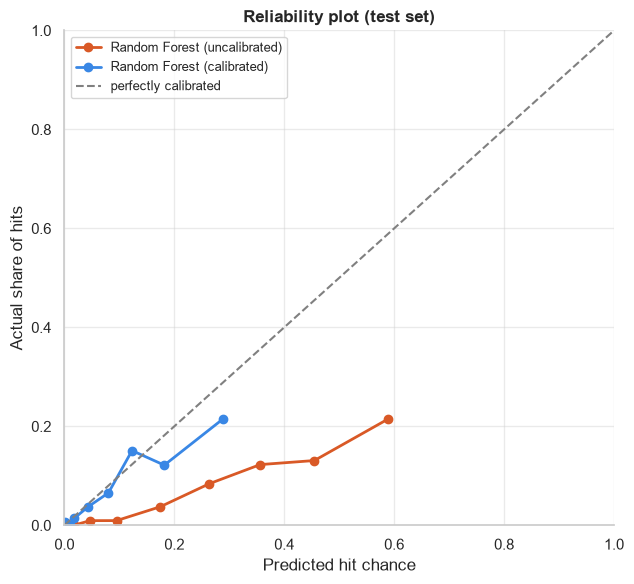

,uncalibrated,calibrated
mean predicted hit chance,0.250,0.093
Brier score (lower = better),0.110,0.066
ROC-AUC,0.784,0.783


In [10]:
best_name = max(cv_auc, key=cv_auc.get)
base = {"Decision tree": tree, "Random Forest": rf, "AdaBoost (stumps)": ada}[best_name]
from sklearn.base import clone
cal = CalibratedClassifierCV(clone(base), method="isotonic", cv=cv)
if best_name == "AdaBoost (stumps)":
    cal.fit(X_train, ytr, sample_weight=sw)
else:
    cal.fit(X_train, ytr)
p_raw, p_cal = base.predict_proba(X_test)[:, 1], cal.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(6.5, 6))
for p, label, color in [(p_raw, f"{best_name} (uncalibrated)", "#d95926"), (p_cal, f"{best_name} (calibrated)", "#3987e5")]:
    frac, mean_pred = calibration_curve(yte, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", lw=2, color=color, label=label)
ax.plot([0, 1], [0, 1], "--", color="gray", label="perfectly calibrated")
ax.set_xlabel("Predicted hit chance"); ax.set_ylabel("Actual share of hits"); ax.legend(fontsize=9)
ax.set_title("Reliability plot (test set)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG / "calibration.png", dpi=120); plt.show()

cal_met = evaluate.classification_metrics(yte, (p_cal >= 0.5).astype(int), p_cal)
pd.DataFrame({"uncalibrated": {"mean predicted hit chance": p_raw.mean(), "Brier score (lower = better)": brier_score_loss(yte, p_raw), "ROC-AUC": rows[best_name]["roc_auc"]},
              "calibrated": {"mean predicted hit chance": p_cal.mean(), "Brier score (lower = better)": brier_score_loss(yte, p_cal), "ROC-AUC": cal_met["roc_auc"]}}).round(3)

This shows why calibration matters. The **uncalibrated forest over-estimates hit chances** (orange line far below the diagonal; its average predicted chance is 25% while only 7.6% of test songs are hits), because class weights inflate hit probabilities on purpose. After calibration (blue) the points follow the diagonal much better, the average predicted chance (9.3%) matches the real hit rate, and the **Brier score drops from 0.110 to 0.066**. ROC-AUC is unchanged (0.78): calibration fixes the *probabilities*, not the *ranking*. The app therefore shows calibrated hit chances.

### Choosing a decision threshold for the calibrated model
Calibrated probabilities are honest, but with only ~9% hits they rarely exceed 50%, so the usual 0.5 cut-off almost never says "hit". We pick the threshold that maximises F1 **using cross-validated predictions on the training set** (never the test set), then apply it once to the test set.

In [11]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(CalibratedClassifierCV(clone(base), method="isotonic", cv=3), X_train, ytr, cv=cv, method="predict_proba",
                        params={"sample_weight": sw} if best_name == "AdaBoost (stumps)" else None)[:, 1]
ths = np.linspace(0.05, 0.6, 56)
f1s = [evaluate.classification_metrics(ytr, (oof >= t).astype(int))["f1"] for t in ths]
THRESH = float(ths[int(np.argmax(f1s))])
final_met = evaluate.classification_metrics(yte, (p_cal >= THRESH).astype(int), p_cal)
evaluate.log_score("P5 Hit Predictor", f"{best_name} (calibrated)", "hit", final_met)
evaluate.save_predictions("hit", f"{best_name} (calibrated)", X_test.index, (p_cal >= THRESH).astype(int), p_cal, y_true=yte)
print(f"Threshold chosen on training CV predictions: {THRESH:.2f}")
pd.Series(final_met).round(3)

Threshold chosen on training CV predictions: 0.18


accuracy     0.800
macro_f1     0.575
precision    0.185
recall       0.477
f1           0.266
roc_auc      0.783
dtype: float64

This shows that with a threshold of **0.18** (chosen on training-set CV predictions), the calibrated forest catches **48% of hits with 18.5% precision (F1 0.27)**. For a record label this is a useful shortlist: a flagged song is about 2.4× more likely to be a hit than a random song (18.5% vs 7.6%), but most flagged songs still won't be hits.

## 9. An honest note on the limits
Sound explains only part of a hit. Popularity depends heavily on things that are **not in the audio**: the artist's existing fame, label marketing, playlist placement, release timing, social media trends and luck. Two songs with near-identical features can have popularity 10 and 90. Part of what our models detect is also **genre-level** (hip-hop and country have more hits in our data than classical), not "hit-ness" within a genre. A ROC-AUC around 0.8 means the model ranks hits above non-hits much better than chance, but its precision is modest: most songs it flags are not hits. It is a screening tool ("this demo sounds like past hits"), not a hit guarantee.

## 10. Save the model and a "hit profile" for the app's explanations
- `hit_model.joblib`: calibrated best model + threshold + feature list.
- `hit_profile.json`: forest importances and average feature values of hits vs non-hits, used to write the "why" reasons in the app.

In [12]:
joblib.dump({"model": cal, "name": f"{best_name} (calibrated)", "features": feature_names, "threshold": THRESH}, MODELS / "hit_model.joblib")
joblib.dump({"model": small_tree, "features": feature_names}, MODELS / "tree_depth3.joblib")
hit_profile = {"importance": imp.round(4).to_dict(),
               "hit_means": train_songs[train_songs.hit == 1][data.AUDIO_FEATURES + ["explicit"]].mean().round(4).to_dict(),
               "nonhit_means": train_songs[train_songs.hit == 0][data.AUDIO_FEATURES + ["explicit"]].mean().round(4).to_dict(),
               "threshold": THRESH, "hit_rate": float(train_songs.hit.mean())}
(MODELS / "hit_profile.json").write_text(json.dumps(hit_profile, indent=2))
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['hit_model.joblib', 'hit_profile.json', 'tree_depth3.joblib']


## Results summary

| Model | CV ROC-AUC (train) | Test ROC-AUC | Test F1 | Precision | Recall |
|---|---|---|---|---|---|
| Decision tree (Gini, depth 5) | 0.737 | 0.729 | 0.256 | 0.153 | 0.769 |
| **Random Forest** (300 trees, min leaf 10) | **0.790** | **0.784** | 0.262 | 0.203 | 0.369 |
| AdaBoost (200 stumps, lr 0.5) | 0.782 | 0.757 | 0.241 | 0.141 | 0.846 |
| Random Forest, calibrated, threshold 0.18 | | 0.783 | **0.266** | 0.185 | 0.477 |
| *Baseline: random by hit rate* | | *0.465* | *0.027* | | |

**Takeaways**
- Hits are rare (9%), so accuracy is misleading; ROC-AUC and F1 tell the real story.
- **Ensembles beat a single tree** (forest ROC-AUC 0.78 vs 0.73): averaging many trees reduces variance.
- **What makes a hit (in our data):** danceable, energetic, louder, less acoustic and shorter songs; heavy-metal and classical almost never chart.
- Calibration turns inflated scores into honest probabilities (Brier 0.110 → 0.066) without hurting the ranking.
- **Honest limit:** sound explains only part of a hit; fame, marketing and luck are not in the audio, so precision stays low.

## Questions you may be asked

**1. Gini vs entropy: what is each measuring?**
Both measure how mixed a group of songs is (0 = all hits or all non-hits). Gini is the probability that two randomly picked songs from the group have different labels; entropy is the average "surprise" (in bits) of a song's label. They almost always choose the same splits; Gini is slightly faster to compute. In our CV search the best tree used Gini (depth 5).

**2. Why does a random forest beat a single tree? Bagging vs boosting?**
A single deep tree has high variance: small changes in the training songs change its splits a lot. A forest trains many trees on different bootstrap samples with random feature subsets, so their errors are partly independent, and averaging their votes cancels much of the noise (our CV ROC-AUC: tree 0.737 → forest 0.790). **Bagging** trains trees independently and in parallel and averages them (reduces variance). **Boosting** trains small trees one after another, each focusing (via higher weights) on the songs the previous ones got wrong, and adds them up (reduces bias).

**3. Why not just use accuracy here?**
Only about 8–9% of songs are hits, so predicting "not a hit" for every song already gives ~92% accuracy while catching zero hits. Accuracy hides that. F1, precision, recall and ROC-AUC focus on how well we find the rare hits.

**4. What does ROC-AUC = 0.5 mean? And 1.0?**
0.5 means the model ranks a random hit above a random non-hit only half the time, i.e. no better than a coin flip (the diagonal on the ROC plot). 1.0 means every hit gets a higher score than every non-hit: a perfect ranking. Our best model's test ROC-AUC is 0.78: it ranks a random hit above a random non-hit 78% of the time, which is clearly better than chance but far from perfect.

**5. If danceability is most important, does that mean it causes hits?**
No. Importance only says the model *uses* that feature to separate hits from non-hits in this dataset. It is correlation, not causation: danceable songs may be hits because danceable genres (hip-hop, pop-leaning country, edm) get more streams and playlisting, or because of confounders such as big-label production. Making a song more danceable would not guarantee it becomes a hit; only an experiment could show causation.